# CHE F315 — Gas Turbine PEMS (BITS Goa)

Predictive emissions monitoring for CO and NOX from nine gas-turbine sensors.
The notebook follows **Prof. Riju De's seven presentation deliverables**:
data/problem, EDA/outliers/VIF, MLE, PCA/K-Means, regression CV vs chronology,
outlier ablation, and Q90/Q95 alerts with conclusions.

Every stage is executed from `src/` with seed 42. The nine sensors
(`AT, AP, AH, AFDP, GTEP, TIT, TAT, TEY, CDP`) are the only predictors.
CO and NOX are modeled independently; `year` is split metadata only.
All scalers, PCA/K-Means fits, thresholds and trimming limits are fitted on
training partitions and never on validation or test rows.

## 1. Data and problem

**Method.** Load `data/raw/gas_turbine_full.csv`, validate the exact
36,733 × 12 schema and year counts, coerce the 11 analysis variables to finite
floats, and write `data/processed/gas_turbine_modeling.csv`. Show both
evaluation timelines: a random 80/20 holdout with five-fold tuning on the 80%,
and a locked chronology (2011–2013 train, 2014 validation, 2015 test).

**Leakage control.** `year` is never a predictor. The opposite emissions target
is excluded from every feature matrix. 2015 is locked and is only scored.

**Interpretation.** The row counts must match the verified data contract
exactly; no rows, duplicates or emissions spikes are removed.

In [1]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PYTHON = ROOT / ".venv" / "bin" / "python"


def run_stage(script_name):
    result = subprocess.run(
        [str(PYTHON), str(ROOT / "src" / script_name)],
        cwd=ROOT,
        capture_output=True,
        text=True,
    )
    print(result.stdout[-2500:])
    if result.returncode != 0:
        print(result.stderr[-2500:])
        raise RuntimeError(f"{script_name} failed")
    return result


run_stage("00_load_data.py")
modeling = pd.read_csv(ROOT / "data/processed" / "gas_turbine_modeling.csv")
print("Shape:", modeling.shape)
print("Columns:", list(modeling.columns))
print("Year counts:")
print(modeling["year"].value_counts().sort_index().to_string())
print("Missing analysis values:", int(modeling.isna().sum().sum()))
display(modeling.head())

indices = np.arange(len(modeling))
train_idx, holdout_idx = train_test_split(
    indices, test_size=0.2, shuffle=True, random_state=42
)
print(
    f"Random protocol: {len(train_idx):,} train rows / "
    f"{len(holdout_idx):,} untrimmed holdout rows"
)
years = modeling["year"]
print(
    "Chronological protocol: "
    f"{int((years <= 2013).sum()):,} train (2011-2013) / "
    f"{int((years == 2014).sum()):,} validation (2014) / "
    f"{int((years == 2015).sum()):,} locked test (2015)"
)
sensors = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
assert "CO" not in sensors and "NOX" not in sensors and "year" not in sensors
print("Predictors are the nine sensors only; targets are modeled independently.")

Processed shape: (36733, 12)
Year counts:
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
Missing analysis values: 0
Wrote /home/samar_perelman$/code/che-f315-gas-turbine-pems/data/processed/gas_turbine_modeling.csv

Shape: (36733, 12)
Columns: ['year', 'AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX']
Year counts:
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
Missing analysis values: 0


,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


Random protocol: 29,386 train rows / 7,347 untrimmed holdout rows
Chronological protocol: 22,191 train (2011-2013) / 7,158 validation (2014) / 7,384 locked test (2015)
Predictors are the nine sensors only; targets are modeled independently.


## 2. EDA, outliers and VIF

**Method.** On the random 80% training partition, report descriptive
statistics, 1.5×IQR and μ±3s outlier limits for all 11 analysis variables.
Sensor VIF is `1/(1-R²)` from regressing each sensor on the other eight.

**Leakage control.** All limits and VIF regressions use training rows only.
The holdout is untouched.

**Interpretation.** Table 01 shows the emissions targets are strongly
right-skewed (CO especially) with spikes beyond the IQR fence.
High VIF for mechanically coupled sensors motivates PCR and ridge
regularization; the correlation heatmap shows the same dependence structure.

0450   29.091000   34.276300   40.7160        0   14.074125   38.101125             4   12.962482    38.149461                4  30.349381
   TIT 29386 1081.404019 17.554768 1000.800000 1035.400000 1071.600000 1085.90000 1097.000000 1100.300000 1100.9000        0 1033.500000 1135.100000           227 1028.739716  1134.068322              118  38.429868
   TAT 29386  546.159630  6.830996  511.040000  525.217000  544.692500  549.88000  550.040000  550.420000  550.6100        0  536.671250  558.061250          3934  525.666643   566.652618              329  10.206208
   TEY 29386  133.479425 15.620379  100.020000  104.148500  124.312500  133.73000  144.167500  166.373000  179.5000        0   94.530000  173.950000            20   86.618287   180.340563                0 255.610822
   CDP 29386   12.058924  1.089275    9.851800   10.187000   11.425000   11.96400   12.868750   14.288000   15.1590        0    9.259375   15.034375             5    8.791099    15.326750                0 250.9951

,column,n,mean,std,min,q01,q25,median,q75,q99,max,missing,iqr_low,iqr_high,iqr_outliers,sigma3_low,sigma3_high,sigma3_outliers,vif
0,AT,29386,17.716960,7.429408,-6.234800,2.790610,11.802250,17.82300,23.661750,32.163150,35.8220,0,-5.987000,41.451000,2,-4.571263,40.005183,18,8.248592
1,AP,29386,1013.034611,6.437833,986.250000,998.070000,1008.800000,1012.60000,1016.900000,1029.300000,1036.6000,0,996.650000,1029.050000,513,993.721113,1032.348109,167,1.505939
2,AH,29386,77.952101,14.427552,25.987000,40.789250,68.331500,80.59450,89.375750,100.080000,100.2000,0,36.765125,120.942125,118,34.669445,121.234756,64,1.557025
3,AFDP,29386,3.926064,0.776481,2.087400,2.458580,3.354125,3.93830,4.380300,6.019765,7.5549,0,1.814862,5.919563,442,1.596621,6.255507,106,2.493433
4,GTEP,29386,25.555972,4.197830,17.698000,18.540850,23.084250,25.10450,29.091000,34.276300,40.7160,0,14.074125,38.101125,4,12.962482,38.149461,4,30.349381
5,TIT,29386,1081.404019,17.554768,1000.800000,1035.400000,1071.600000,1085.90000,1097.000000,1100.300000,1100.9000,0,1033.500000,1135.100000,227,1028.739716,1134.068322,118,38.429868
6,TAT,29386,546.159630,6.830996,511.040000,525.217000,544.692500,549.88000,550.040000,550.420000,550.6100,0,536.671250,558.061250,3934,525.666643,566.652618,329,10.206208
7,TEY,29386,133.479425,15.620379,100.020000,104.148500,124.312500,133.73000,144.167500,166.373000,179.5000,0,94.530000,173.950000,20,86.618287,180.340563,0,255.610822
8,CDP,29386,12.058924,1.089275,9.851800,10.187000,11.425000,11.96400,12.868750,14.288000,15.1590,0,9.259375,15.034375,5,8.791099,15.326750,0,250.995163
9,CO,29386,2.373896,2.245034,0.001594,0.197196,1.182825,1.71395,2.847875,11.004050,44.1030,0,-1.314750,5.345450,2136,-4.361205,9.108997,532,NaN


Largest sensor VIF:
column        vif
   TEY 255.610822
   CDP 250.995163
   TIT  38.429868


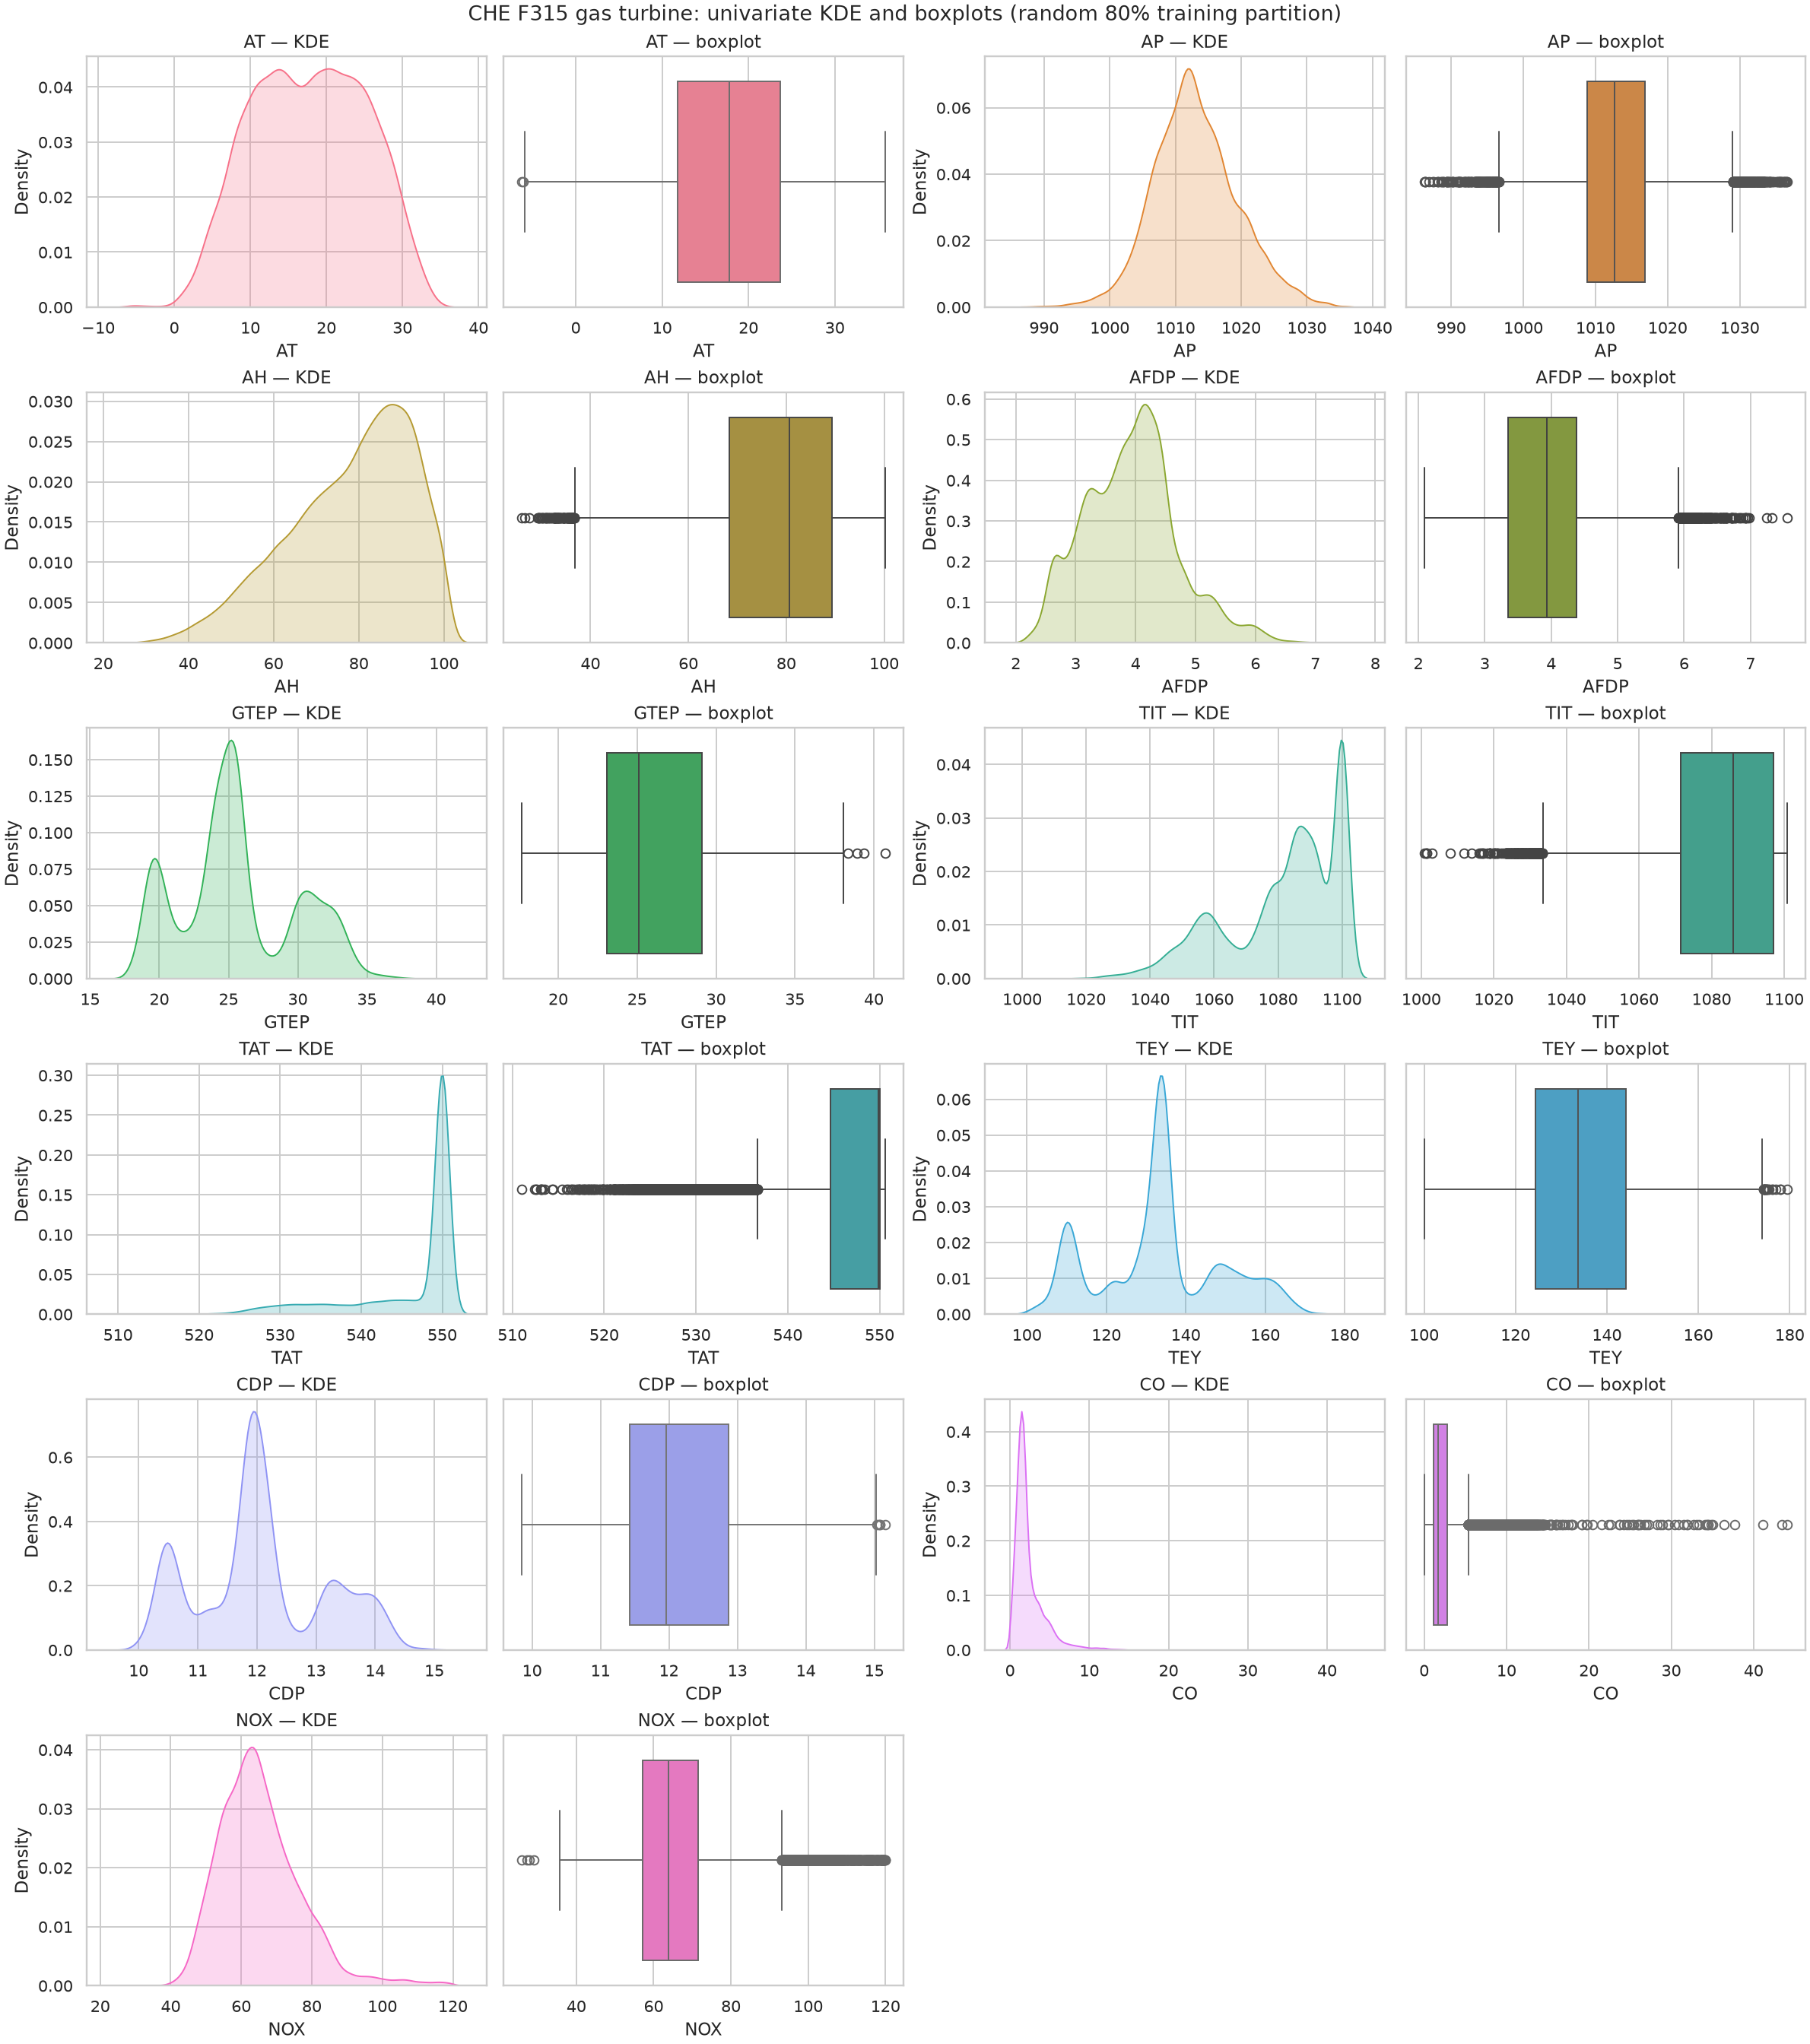

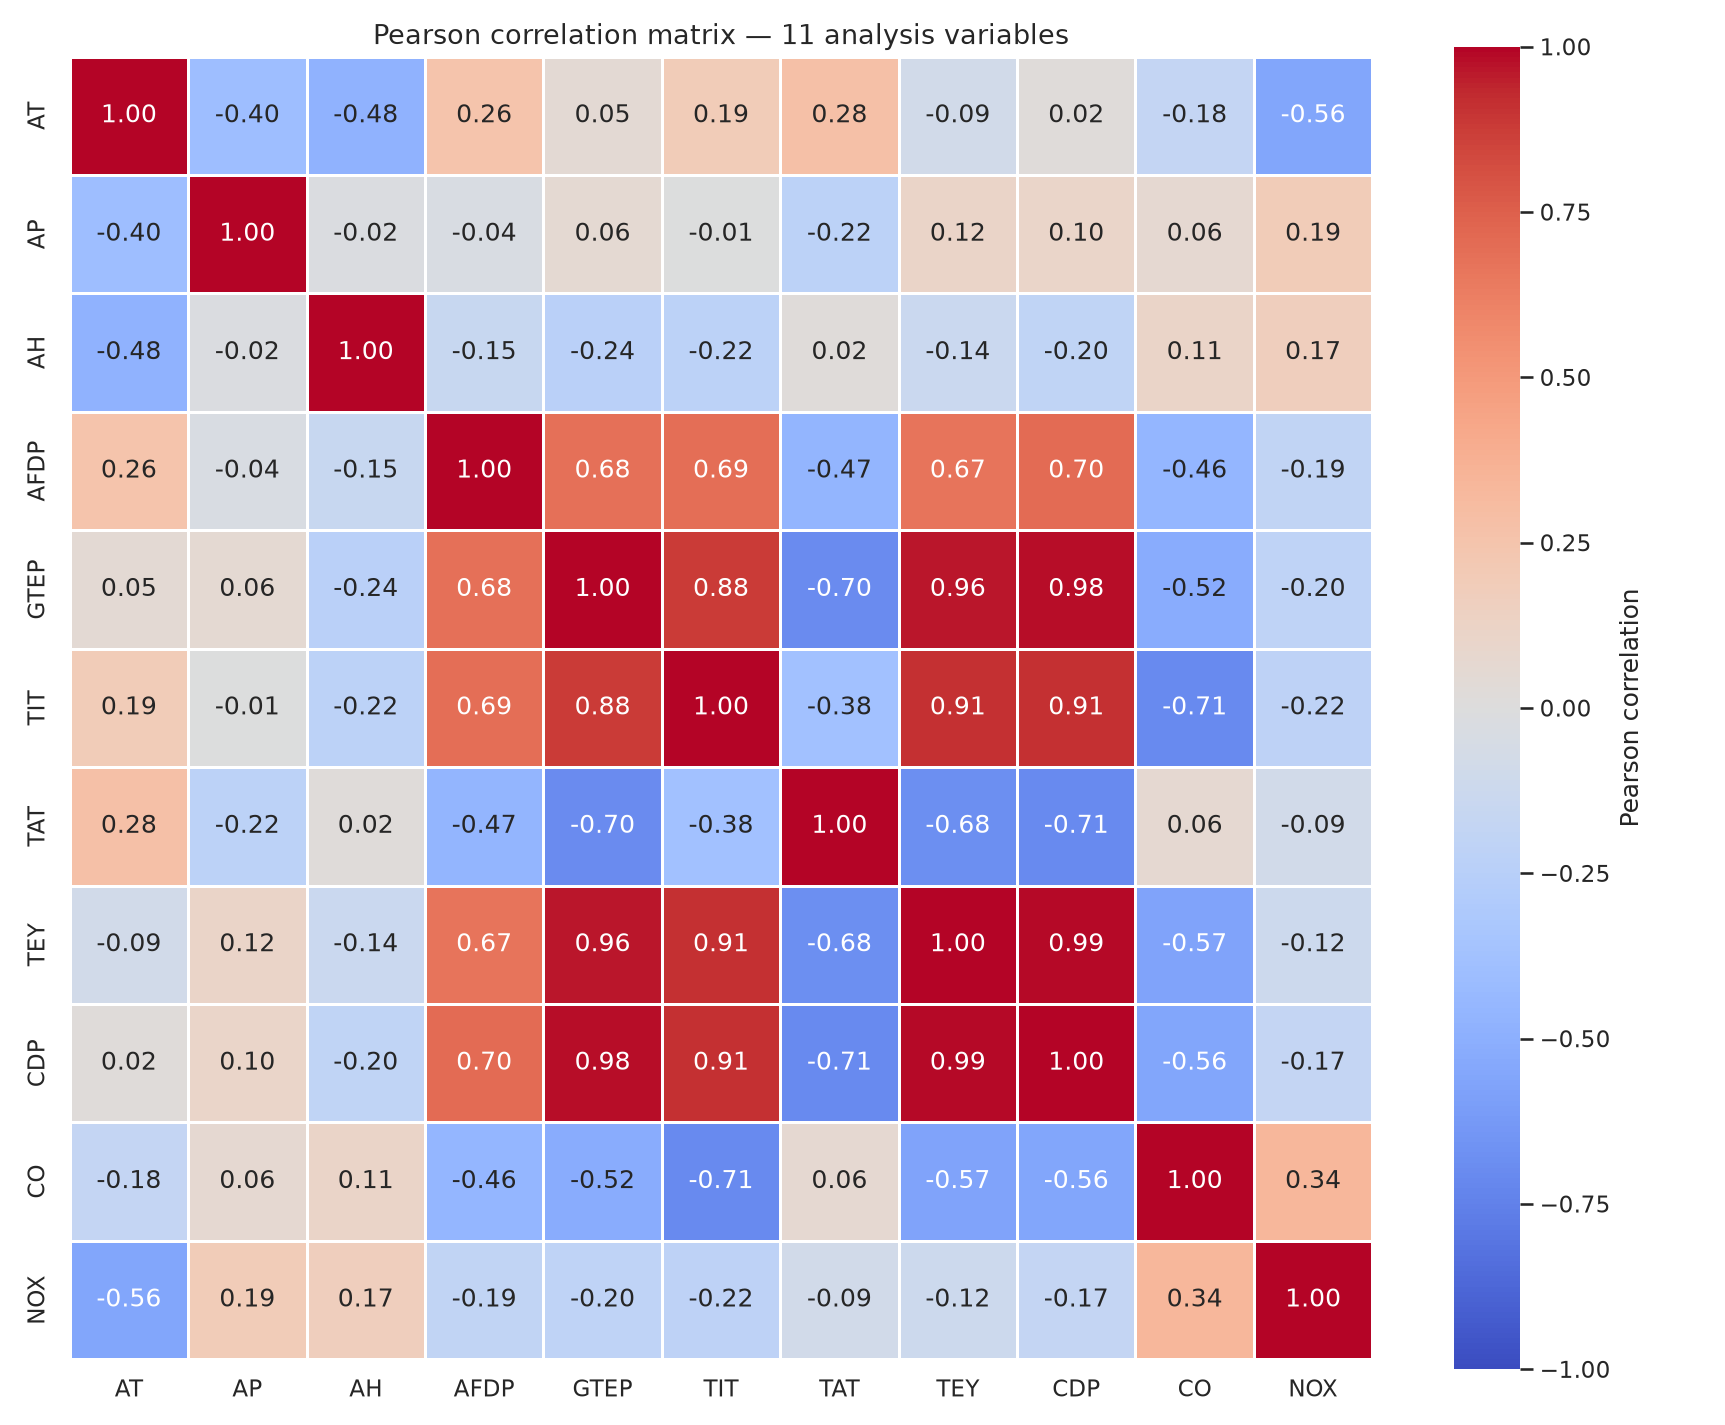

In [2]:
run_stage("01_eda_outliers_mle.py")
table01 = pd.read_csv(ROOT / "results" / "table01_eda_outliers_vif.csv")
display(table01)
print("Largest sensor VIF:")
print(
    table01.dropna(subset=["vif"])
    .sort_values("vif", ascending=False)[["column", "vif"]]
    .head(3)
    .to_string(index=False)
)
display(Image(filename=str(ROOT / "figures" / "fig01_univariate_kde_boxplots.png"), width=1050))
display(Image(filename=str(ROOT / "figures" / "fig02_correlation_heatmap_11x11.png"), width=850))

## 3. Distribution MLE for CO and NOX

**Method.** Fit normal, gamma and lognormal densities by maximum likelihood
(`gamma`/`lognorm` with `floc=0`). Report log-likelihood, AIC and BIC; the
best model is the maximum log-likelihood.

**Leakage control.** MLE parameters are fitted on the random training
partition only.

**Interpretation.** The target histograms are right-tailed. A positive
distribution with a heavy tail should beat the normal in log-likelihood;
AIC/BIC confirm whether the extra tail parameter is justified.

,target,distribution,parameters,n,loglik,aic,bic,best_by_loglik
0,CO,norm,"{""loc"": 2.3738955997209557, ""scale"": 2.2449954...",29386,-65461.488824,130926.977647,130943.554194,False
1,CO,gamma,"{""a"": 1.8195594826043302, ""loc"": 0.0, ""scale"":...",29386,-52155.103235,104314.206470,104330.783017,False
2,CO,lognorm,"{""loc"": 0.0, ""s"": 0.7936007311067489, ""scale"":...",29386,-51513.909858,103031.819716,103048.396263,True
3,NOX,norm,"{""loc"": 65.31102977608386, ""scale"": 11.7194237...",29386,-114023.150101,228050.300202,228066.876749,False
4,NOX,gamma,"{""a"": 33.316769141906136, ""loc"": 0.0, ""scale"":...",29386,-112694.977955,225393.955910,225410.532458,False
5,NOX,lognorm,"{""loc"": 0.0, ""s"": 0.17169561683054252, ""scale""...",29386,-112283.462260,224570.924520,224587.501067,True


Best by log-likelihood:
target distribution         loglik           aic           bic
    CO      lognorm  -51513.909858 103031.819716 103048.396263
   NOX      lognorm -112283.462260 224570.924520 224587.501067


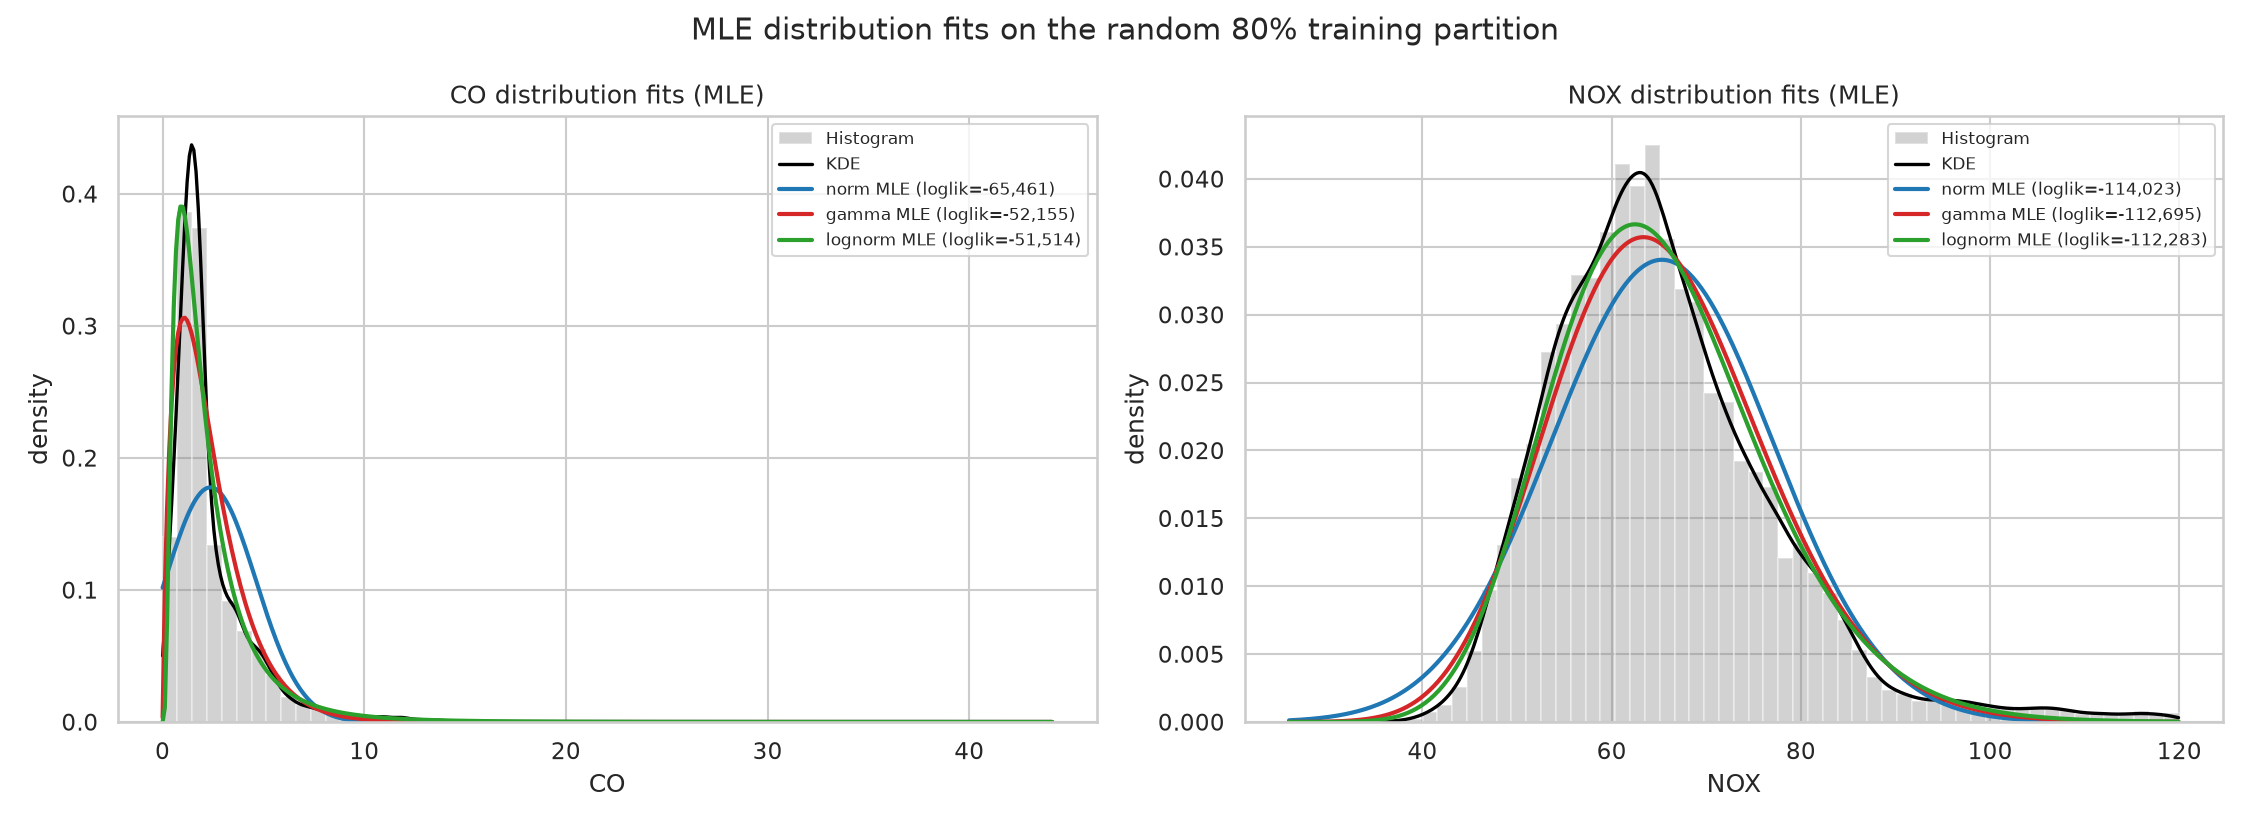

In [3]:
table02 = pd.read_csv(ROOT / "results" / "table02_mle_loglik.csv")
display(table02)
print("Best by log-likelihood:")
print(
    table02[table02["best_by_loglik"].astype(bool)][
        ["target", "distribution", "loglik", "aic", "bic"]
    ].to_string(index=False)
)
display(Image(filename=str(ROOT / "figures" / "fig03_mle_distribution_fits.png"), width=1050))

## 4. PCA structure and K-Means operating regimes

**Method.** Standardize the nine sensors on the training partition, fit full
PCA, and fit `KMeans(k=3, n_init=20, random_state=42)`. Clusters are relabeled
by ascending original-unit TEY centroid so regime IDs are reproducible.

**Leakage control.** Scaler, PCA and K-Means are fitted only on training rows;
regime labels are descriptive and are never used as regression predictors.

**Interpretation.** The scree plot shows how many components carry the
sensor covariance. The biplot and centroid table separate low-, mid- and
high-TEY regimes, matching the turbine load spectrum.

Explained variance ratios: [5.428e-01 1.998e-01 1.094e-01 6.120e-02 5.310e-02 2.780e-02 4.400e-03
 1.100e-03 2.000e-04]
Cumulative variance: [0.5428 0.7427 0.8521 0.9133 0.9664 0.9942 0.9987 0.9998 1.    ]
 cluster  n_members       inertia        AT          AP        AH     AFDP      GTEP         TIT        TAT        TEY       CDP
       0       7010 124978.174613 16.280076 1012.939853 82.175480 3.170445 20.295278 1054.489787 548.407915 112.397689 10.631082
       1      15148 124978.174613 18.455153 1012.674651 77.755764 3.902458 25.129498 1085.150687 549.802009 133.073093 11.981267
       2       7228 124978.174613 17.563624 1013.881023 74.266478 4.708577 31.553334 1099.660717 536.344011 154.782754 13.606864



,cluster,n_members,inertia,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
0,0,7010,124978.174613,16.280076,1012.939853,82.175480,3.170445,20.295278,1054.489787,548.407915,112.397689,10.631082
1,1,15148,124978.174613,18.455153,1012.674651,77.755764,3.902458,25.129498,1085.150687,549.802009,133.073093,11.981267
2,2,7228,124978.174613,17.563624,1013.881023,74.266478,4.708577,31.553334,1099.660717,536.344011,154.782754,13.606864


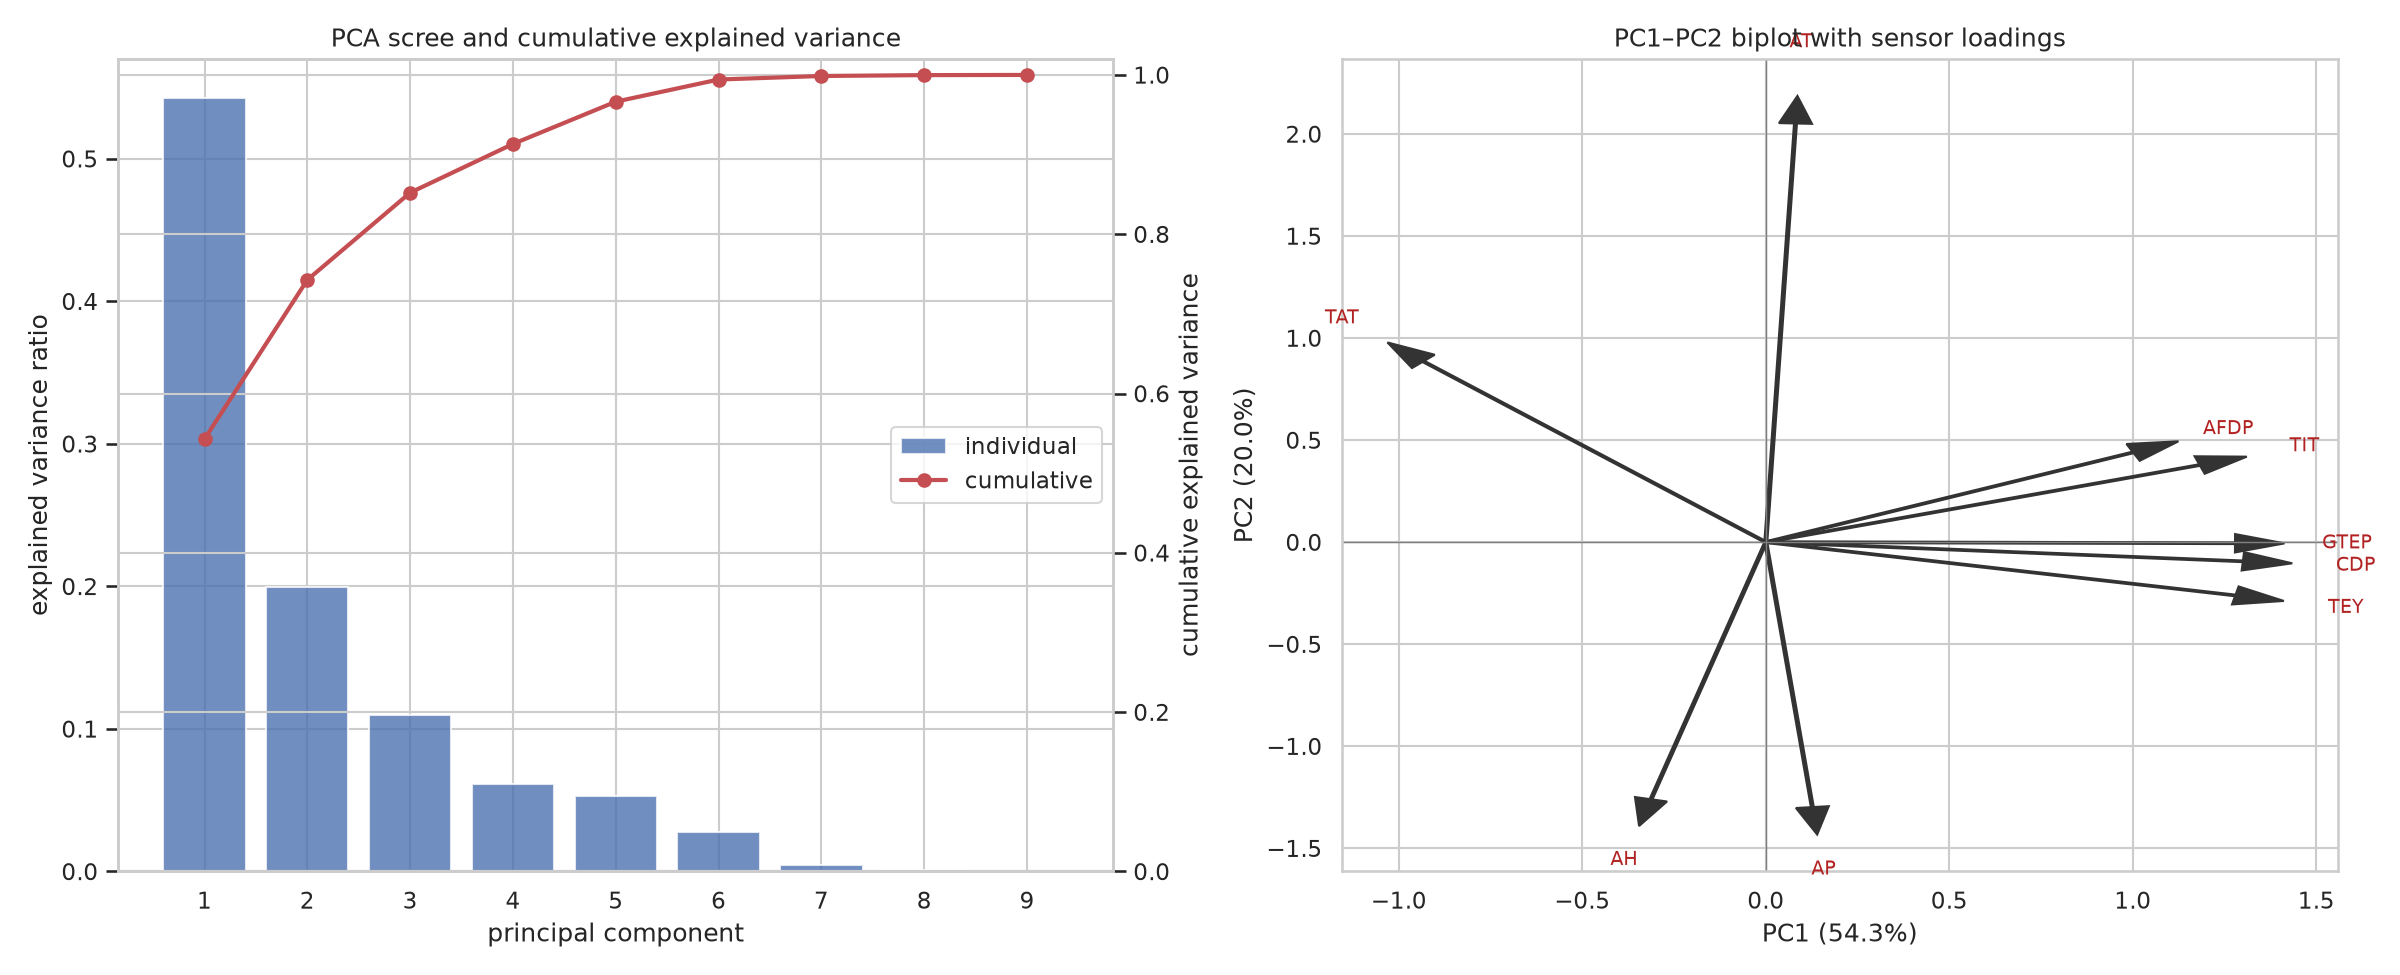

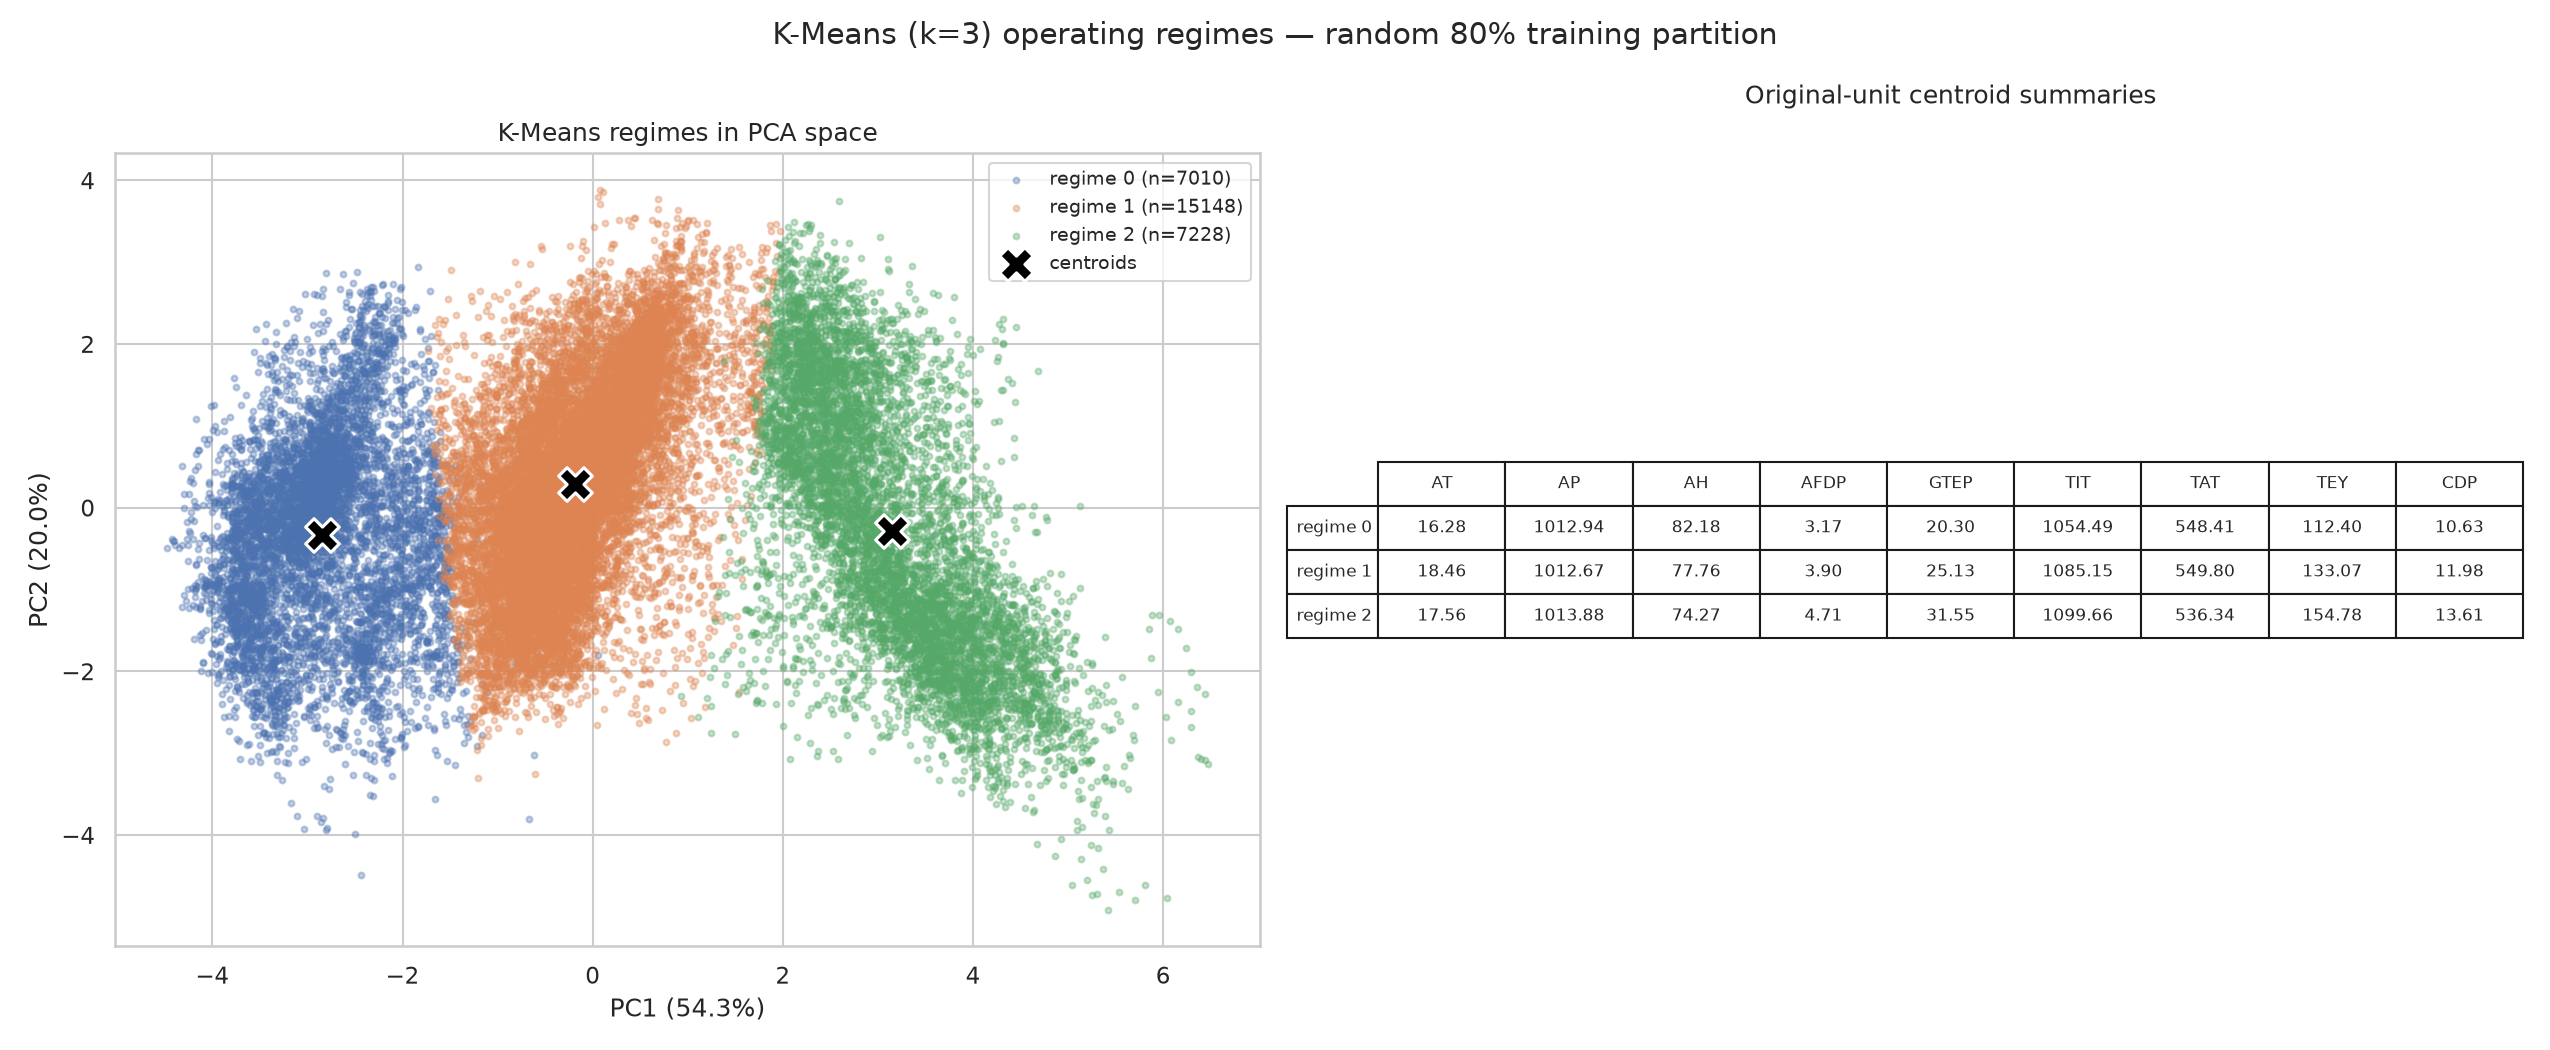

In [4]:
run_stage("02_pca_kmeans.py")
table03 = pd.read_csv(ROOT / "results" / "table03_kmeans_centroids.csv")
display(table03)
display(Image(filename=str(ROOT / "figures" / "fig04_pca_scree_biplot.png"), width=1050))
display(Image(filename=str(ROOT / "figures" / "fig05_kmeans_regimes.png"), width=1050))

## 5. Regression: five-fold CV vs locked chronology

**Method.** For each target independently, train OLS, ridge, lasso, PCR
(2–9 components), degree-2 polynomial ridge and a feed-forward
`MLPRegressor`. Hyperparameters are chosen by minimum five-fold CV RMSE on
the random training partition, or by 2014 RMSE for the chronological protocol.
The selected pipeline is refit and scored once on the untrimmed holdout or
locked 2015 test. A supplementary `log1p(CO)` MLP variant is also fitted.

**Leakage control.** Every scaler, PCA, polynomial expansion, regularization
path and MLP fit is fold-local or training-only. No test/2015 information is
used for selection.

**Interpretation.** Random CV measures interpolation within the same operating
era. The chronological table is the honest deployment estimate because it
holds out a future year; degradation there is temporal drift, not a bug.
Tail RMSE (Q95/Q99) is expected to exceed overall RMSE because spikes are
retained.

981561     54
chronological_2015    NOX Poly2_Ridge                                    {"alpha": 0.1}    -0.028187      10.110585            22191   7158    29349    7384 0.400664   8.617809  74.266640 11.001437    251 14.373713     54
chronological_2015    NOX         MLP {"alpha": 0.0001, "hidden_layer_sizes": [64, 32]}    -0.132289      10.610083            22191   7158    29349    7384 0.018585  11.027785 121.612049  9.452382    251 11.614407     54

            protocol target       model variant  n_train_original  n_train_retained  n_test  test_r2  test_rmse   test_mse  q95_rmse  q95_n  q99_rmse  q99_n
random_5fold_holdout     CO         MLP     Raw             29386             29386    7347 0.776161   1.103247   1.217154  3.796162    356  7.272944     75
random_5fold_holdout     CO         MLP     IQR             29386             22920    7347 0.471331   1.695497   2.874709  7.163133    356 13.874250     75
random_5fold_holdout     CO         MLP 3-sigma             29386     

,protocol,target,model,best_params,cv_rmse_mean,cv_rmse_std,cv_r2_mean,n_train,n_test,test_r2,test_rmse,test_mse,q95_rmse,q95_n,q99_rmse,q99_n
0,random_5fold_holdout,CO,OLS,{},1.481098,0.048934,0.564176,29386,7347,0.556646,1.552674,2.410798,5.571130,356,11.160662,75
1,random_5fold_holdout,CO,Ridge,"{""alpha"": 1.0}",1.481097,0.049002,0.564177,29386,7347,0.556637,1.552690,2.410847,5.571662,356,11.161671,75
2,random_5fold_holdout,CO,Lasso,"{""alpha"": 0.0001}",1.481099,0.049002,0.564176,29386,7347,0.556636,1.552693,2.410855,5.571844,356,11.161992,75
3,random_5fold_holdout,CO,PCR,"{""n_components"": 9}",1.481098,0.048934,0.564176,29386,7347,0.556646,1.552674,2.410798,5.571130,356,11.160662,75
4,random_5fold_holdout,CO,Poly2_Ridge,"{""alpha"": 0.0001}",1.260089,0.048074,0.683959,29386,7347,0.713667,1.247787,1.556973,4.426635,356,8.576006,75
5,random_5fold_holdout,CO,MLP,"{""alpha"": 0.0001, ""hidden_layer_sizes"": [64, 32]}",1.137911,0.069342,0.742700,29386,7347,0.776161,1.103247,1.217154,3.796162,356,7.272944,75
6,random_5fold_holdout,NOX,OLS,{},8.093562,0.109477,0.522899,29386,7347,0.494665,8.183204,66.964831,20.993114,360,31.721120,53
7,random_5fold_holdout,NOX,Ridge,"{""alpha"": 0.1}",8.093560,0.109521,0.522899,29386,7347,0.494672,8.183152,66.963982,20.993515,360,31.722172,53
8,random_5fold_holdout,NOX,Lasso,"{""alpha"": 0.0001}",8.093562,0.109482,0.522899,29386,7347,0.494674,8.183138,66.963750,20.993262,360,31.721606,53
9,random_5fold_holdout,NOX,PCR,"{""n_components"": 9}",8.093562,0.109477,0.522899,29386,7347,0.494665,8.183204,66.964831,20.993114,360,31.721120,53


,protocol,target,model,best_params,val_2014_r2,val_2014_rmse,n_initial_train,n_val,n_train,n_test,test_r2,test_rmse,test_mse,q95_rmse,q95_n,q99_rmse,q99_n
0,chronological_2015,CO,OLS,{},0.410658,1.540591,22191,7158,29349,7384,0.323741,1.837796,3.377495,4.326396,596,8.273346,132
1,chronological_2015,CO,Ridge,"{""alpha"": 100.0}",0.466788,1.465392,22191,7158,29349,7384,0.320233,1.842557,3.395015,4.371432,596,8.310613,132
2,chronological_2015,CO,Lasso,"{""alpha"": 0.001}",0.464409,1.468657,22191,7158,29349,7384,0.330072,1.829173,3.345875,4.331355,596,8.280620,132
3,chronological_2015,CO,PCR,"{""n_components"": 7}",0.458665,1.476512,22191,7158,29349,7384,0.292223,1.880135,3.534907,4.418014,596,8.342944,132
4,chronological_2015,CO,Poly2_Ridge,"{""alpha"": 0.01}",0.551283,1.344281,22191,7158,29349,7384,0.391037,1.743958,3.041391,4.030394,596,7.060707,132
5,chronological_2015,CO,MLP,"{""alpha"": 0.0001, ""hidden_layer_sizes"": [64, 32]}",0.510505,1.404035,22191,7158,29349,7384,0.443031,1.667847,2.781714,4.056517,596,7.100302,132
6,chronological_2015,NOX,OLS,{},0.264638,8.550483,22191,7158,29349,7384,0.258839,9.583370,91.840989,19.050111,251,28.981561,54
7,chronological_2015,NOX,Ridge,"{""alpha"": 0.0001}",0.264637,8.550489,22191,7158,29349,7384,0.258839,9.583371,91.840997,19.050113,251,28.981564,54
8,chronological_2015,NOX,Lasso,"{""alpha"": 0.0001}",0.263588,8.556584,22191,7158,29349,7384,0.258753,9.583922,91.851559,19.052155,251,28.986045,54
9,chronological_2015,NOX,PCR,"{""n_components"": 9}",0.264638,8.550483,22191,7158,29349,7384,0.258839,9.583370,91.840989,19.050111,251,28.981561,54


random_5fold_holdout CO: selected MLP (cv_rmse_mean=1.1379), 2015/holdout RMSE=1.1032, R2=0.7762
random_5fold_holdout NOX: selected MLP (cv_rmse_mean=4.7429), 2015/holdout RMSE=4.4515, R2=0.8505
chronological_2015 CO: selected Poly2_Ridge (val_2014_rmse=1.3443), 2015/holdout RMSE=1.7440, R2=0.3910
chronological_2015 NOX: selected OLS (val_2014_rmse=8.5505), 2015/holdout RMSE=9.5834, R2=0.2588


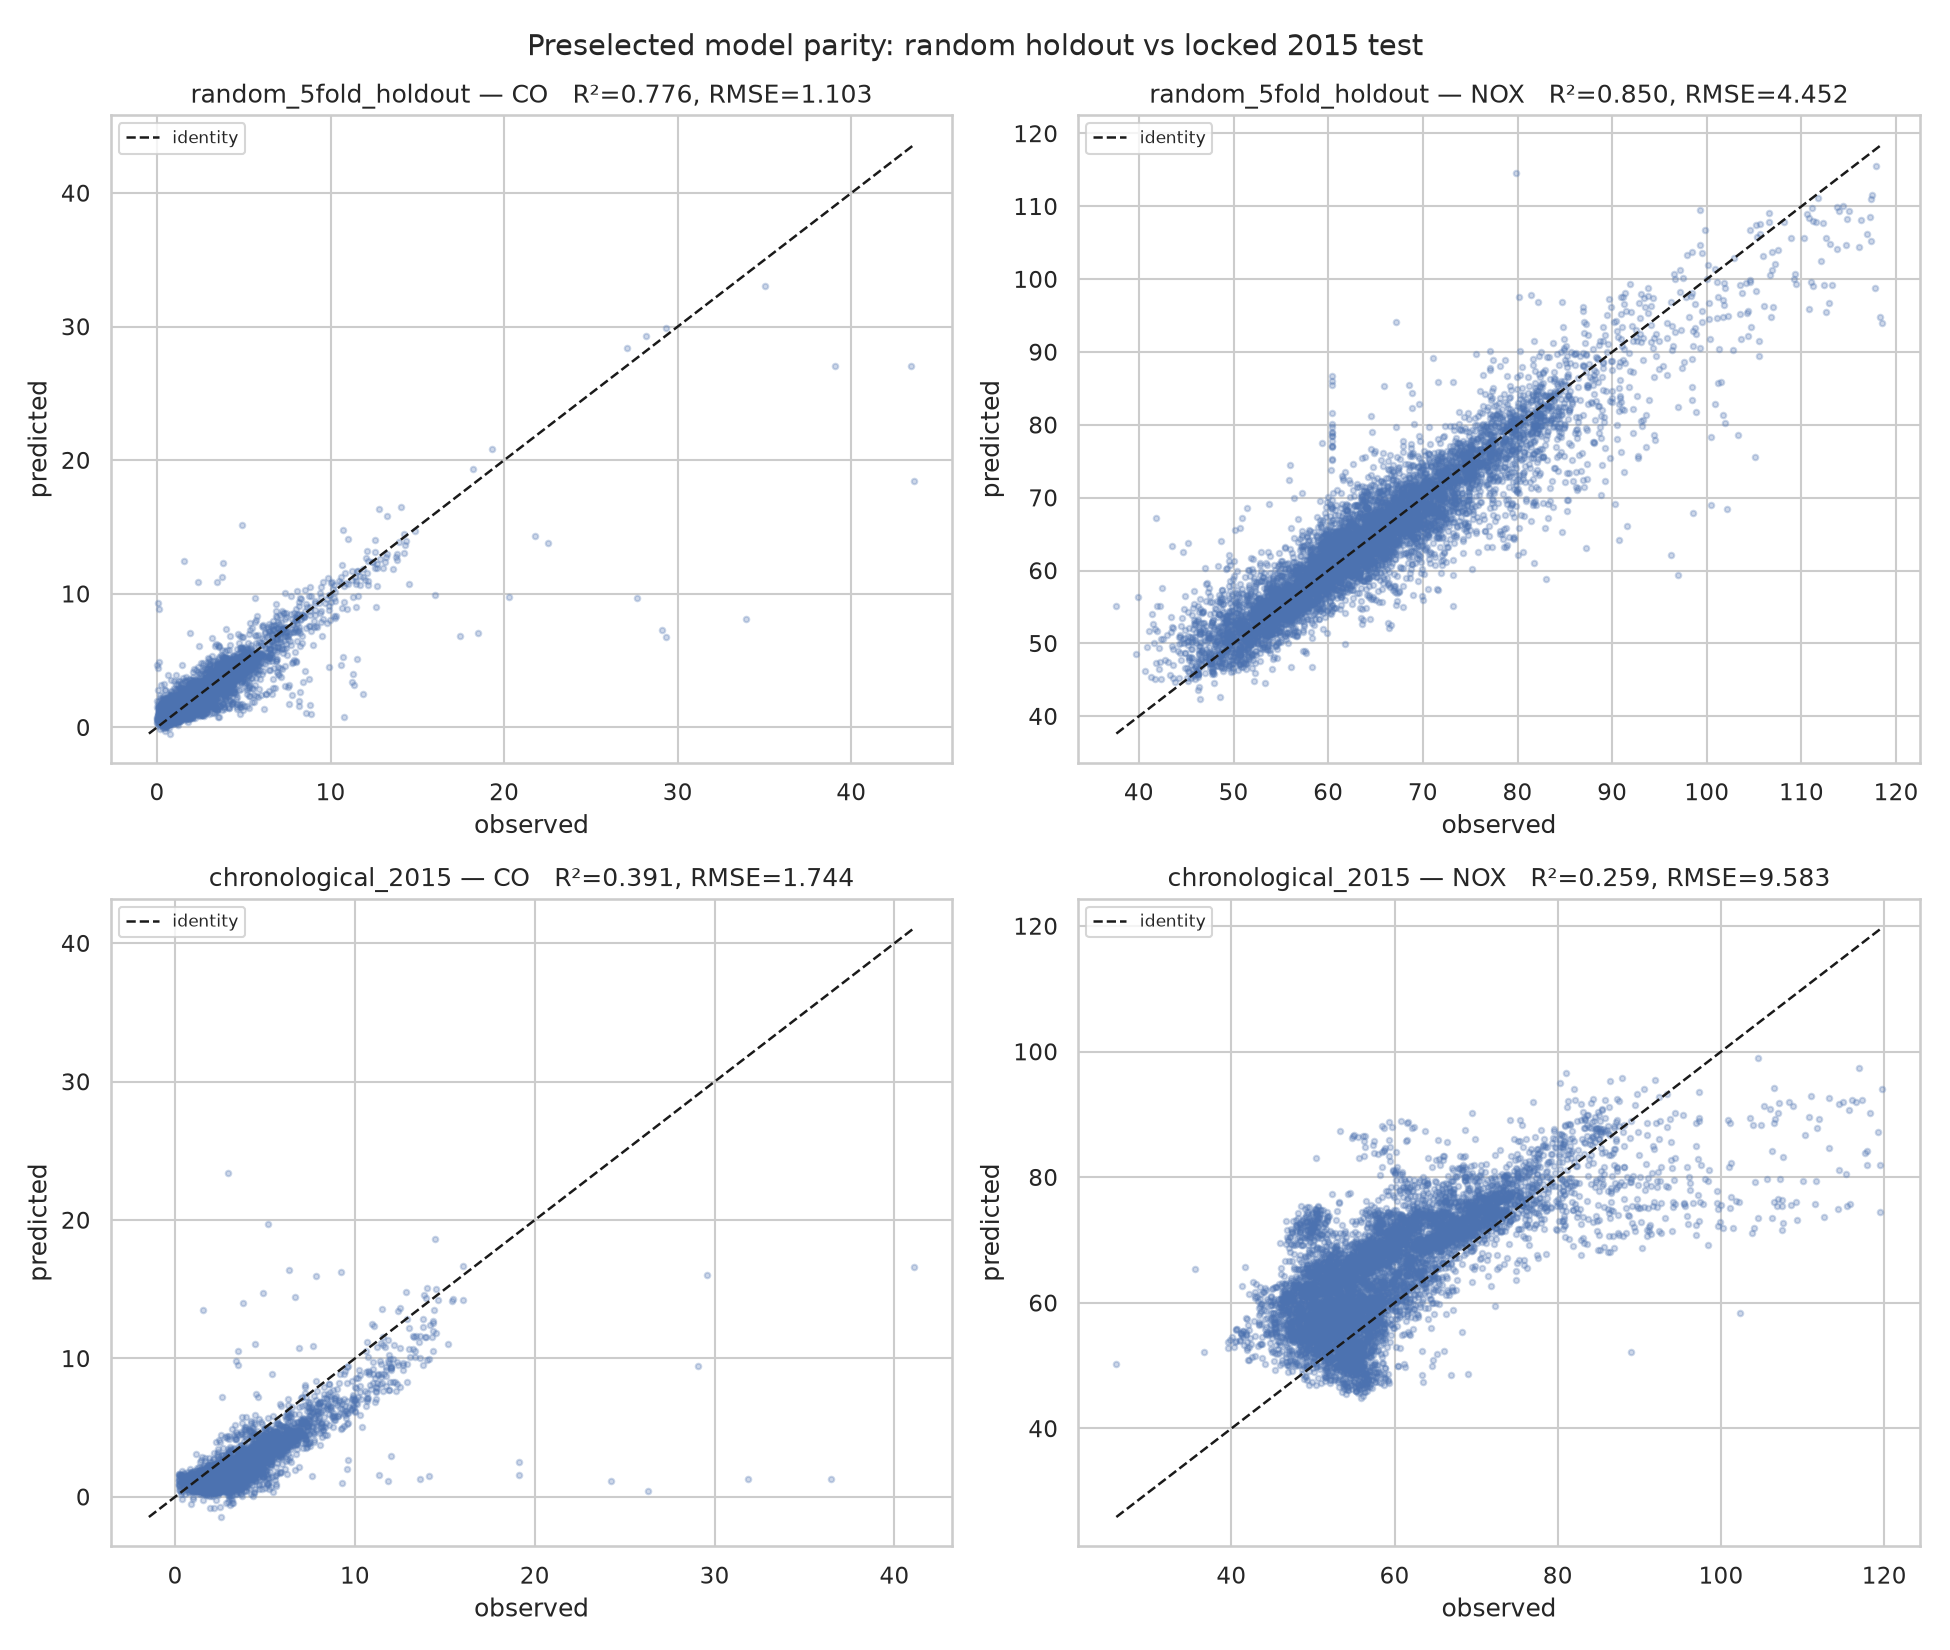

,protocol,target,model,best_params,selection_space,selection_rmse,n_train,n_test,test_r2,test_rmse,test_mse,q95_rmse,q95_n,q99_rmse,q99_n
0,random_5fold_holdout,CO,MLP_log1p,"{""alpha"": 0.001, ""hidden_layer_sizes"": [64, 32]}",cv_rmse_mean,0.227048,29386,7347,0.765677,1.128788,1.274162,4.154405,356,7.986033,75
1,chronological_2015,CO,MLP_log1p,"{""alpha"": 0.001, ""hidden_layer_sizes"": [64, 32]}",val_2014_rmse,0.342190,29349,7384,0.354641,1.795318,3.223168,4.388863,596,7.260088,132


In [5]:
run_stage("03_train_regression_cv.py")
table04 = pd.read_csv(ROOT / "results" / "table04_regression_5fold_cv.csv")
table05 = pd.read_csv(ROOT / "results" / "table05_regression_chronological_2015.csv")
display(table04)
display(table05)
for protocol, frame in [
    ("random_5fold_holdout", table04),
    ("chronological_2015", table05),
]:
    for target in ["CO", "NOX"]:
        column = "cv_rmse_mean" if protocol == "random_5fold_holdout" else "val_2014_rmse"
        best = frame[frame["target"] == target].sort_values(column).iloc[0]
        print(
            f"{protocol} {target}: selected {best['model']} "
            f"({column}={best[column]:.4f}), 2015/holdout RMSE="
            f"{best['test_rmse']:.4f}, R2={best['test_r2']:.4f}"
        )
display(Image(filename=str(ROOT / "figures" / "fig06_parity_cv_vs_chronological.png"), width=1000))
if (ROOT / "results" / "table04b_log1p_co_variant.csv").exists():
    display(pd.read_csv(ROOT / "results" / "table04b_log1p_co_variant.csv"))

## 6. Outlier ablation on untrimmed test data

**Method.** Freeze the Raw reference model selected without test information.
Refit it after removing training rows outside IQR or μ±3s limits computed on
`sensors + target`; keep Raw, IQR and 3-sigma test evaluations on exactly the
same untrimmed rows with Raw-derived Q95/Q99 thresholds.

**Leakage control.** Trimming is training-only; validation/test spikes are
never removed and test targets never set thresholds.

**Interpretation.** `n_test` must be identical across variants. Any tail-RMSE
improvement from trimming would be suspect; the expected result is that
trimming changes the fitted function but cannot hide hard test spikes.

,protocol,target,model,variant,n_train_original,n_train_retained,n_test,test_r2,test_rmse,test_mse,q95_rmse,q95_n,q99_rmse,q99_n
0,random_5fold_holdout,CO,MLP,Raw,29386,29386,7347,0.776161,1.103247,1.217154,3.796162,356,7.272944,75
1,random_5fold_holdout,CO,MLP,IQR,29386,22920,7347,0.471331,1.695497,2.874709,7.163133,356,13.874250,75
2,random_5fold_holdout,CO,MLP,3-sigma,29386,28241,7347,0.598976,1.476694,2.180625,6.057875,356,12.561604,75
3,random_5fold_holdout,NOX,MLP,Raw,29386,29386,7347,0.850462,4.451534,19.816153,9.496293,360,9.637748,53
4,random_5fold_holdout,NOX,MLP,IQR,29386,24156,7347,0.750517,5.749816,33.060380,13.791721,360,20.771877,53
5,random_5fold_holdout,NOX,MLP,3-sigma,29386,28279,7347,0.835650,4.666802,21.779040,11.479167,360,17.173264,53
6,chronological_2015,CO,Poly2_Ridge,Raw,29349,29349,7384,0.391037,1.743958,3.041391,4.030394,596,7.060707,132
7,chronological_2015,CO,Poly2_Ridge,IQR,29349,21333,7384,0.023061,2.208892,4.879203,5.855512,596,10.070232,132
8,chronological_2015,CO,Poly2_Ridge,3-sigma,29349,28322,7384,0.415288,1.708881,2.920274,4.304055,596,7.864968,132
9,chronological_2015,NOX,OLS,Raw,29349,29349,7384,0.258839,9.583370,91.840989,19.050111,251,28.981561,54


Untrimmed test-row counts by protocol (must be constant across variants):
protocol
chronological_2015      [7384]
random_5fold_holdout    [7347]
Retained training rows:
            protocol target variant  n_train_original  n_train_retained
random_5fold_holdout     CO     Raw             29386             29386
random_5fold_holdout     CO     IQR             29386             22920
random_5fold_holdout     CO 3-sigma             29386             28241
random_5fold_holdout    NOX     Raw             29386             29386
random_5fold_holdout    NOX     IQR             29386             24156
random_5fold_holdout    NOX 3-sigma             29386             28279
  chronological_2015     CO     Raw             29349             29349
  chronological_2015     CO     IQR             29349             21333
  chronological_2015     CO 3-sigma             29349             28322
  chronological_2015    NOX     Raw             29349             29349
  chronological_2015    NOX     IQR    

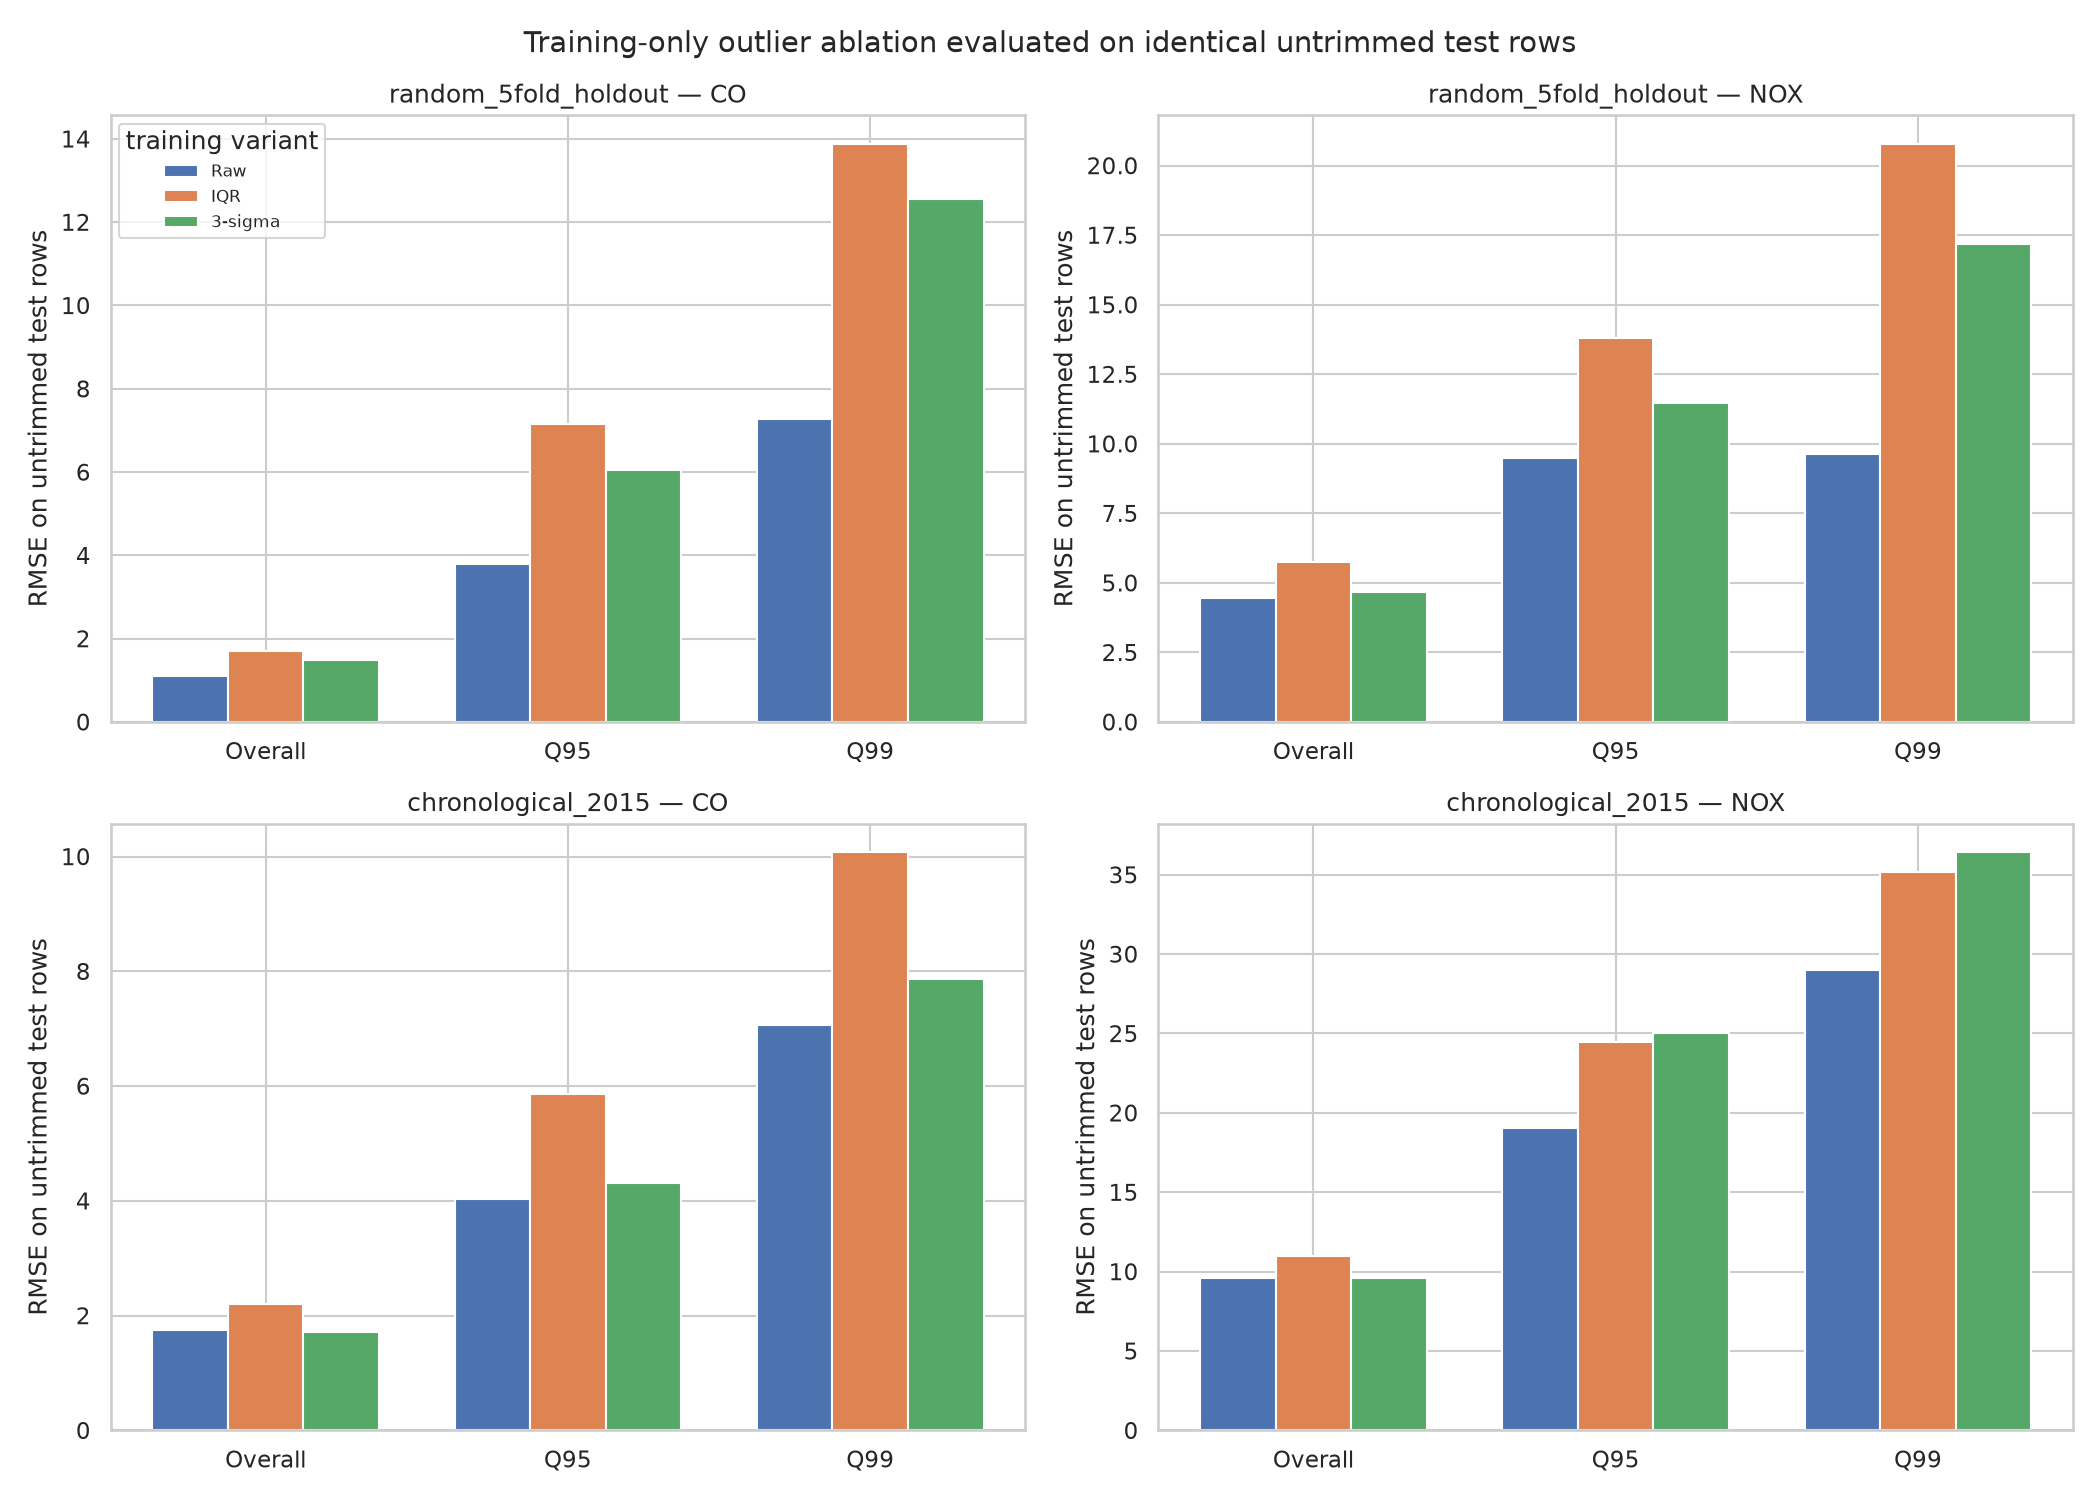

In [6]:
table06 = pd.read_csv(ROOT / "results" / "table06_outlier_ablation_untrimmed_test.csv")
display(table06)
print("Untrimmed test-row counts by protocol (must be constant across variants):")
print(table06.groupby("protocol")["n_test"].unique().to_string())
print("Retained training rows:")
print(table06[["protocol", "target", "variant", "n_train_original", "n_train_retained"]].to_string(index=False))
display(Image(filename=str(ROOT / "figures" / "fig07_outlier_ablation_tails.png"), width=1050))

## 7. Q90/Q95 exceedance alerts and conclusions

**Method.** Threshold each target at its protocol-training Q90/Q95 linear
quantile, label `z = 1[y > τ]`, and fit standardized logistic regression
(`C=1.0`, balanced classes, lbfgs, max_iter=2000) on the nine sensors with a
fixed 0.5 alert probability. Report accuracy, precision, recall, F1, ROC-AUC,
PR-AUC and confusion counts.

**Leakage control.** Thresholds and classifiers are training-only. The
chronological classifier is fitted on 2011–2014 after the policy is fixed and
scored once on 2015; no alert threshold is tuned on test data.

**Interpretation and deployment.** High recall is the priority for emissions
alerts, with precision indicating operator workload. Rare Q95 events have
lower prevalence and noisier precision. Sensor-only alerts are screening tools,
not certified CEMS replacements; drift monitoring, periodic refits and
human verification are required before deployment.

random_5fold_holdout CO Q90: AUROC=0.955 F1=0.584
random_5fold_holdout CO Q95: AUROC=0.960 F1=0.434
random_5fold_holdout NOX Q90: AUROC=0.908 F1=0.482
random_5fold_holdout NOX Q95: AUROC=0.925 F1=0.388
chronological_2015 CO Q90: AUROC=0.947 F1=0.776
chronological_2015 CO Q95: AUROC=0.956 F1=0.649
chronological_2015 NOX Q90: AUROC=0.947 F1=0.242
chronological_2015 NOX Q95: AUROC=0.962 F1=0.193

            protocol target              model quantile  threshold  n_train  n_test  train_prevalence  test_prevalence  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  test_pr_auc   tn   fp  fn  tp
random_5fold_holdout     CO LogisticRegression      Q90    4.78300    29386    7347          0.100014         0.093916       0.876140        0.426471     0.924638 0.583715      0.955433     0.807187 5799  858  52 638
random_5fold_holdout     CO LogisticRegression      Q95    6.15205    29386    7347          0.050024         0.048455       0.883490        0.283737     0.921348 0.4338

,protocol,target,model,quantile,threshold,n_train,n_test,train_prevalence,test_prevalence,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,tn,fp,fn,tp
0,random_5fold_holdout,CO,LogisticRegression,Q90,4.78300,29386,7347,0.100014,0.093916,0.876140,0.426471,0.924638,0.583715,0.955433,0.807187,5799,858,52,638
1,random_5fold_holdout,CO,LogisticRegression,Q95,6.15205,29386,7347,0.050024,0.048455,0.883490,0.283737,0.921348,0.433862,0.960386,0.798692,6163,828,28,328
2,random_5fold_holdout,NOX,LogisticRegression,Q90,80.10400,29386,7347,0.099980,0.099224,0.820199,0.337541,0.843621,0.482164,0.908375,0.690437,5411,1207,114,615
3,random_5fold_holdout,NOX,LogisticRegression,Q95,85.21250,29386,7347,0.050024,0.049000,0.865387,0.249402,0.869444,0.387616,0.925169,0.687067,6045,942,47,313
4,chronological_2015,CO,LogisticRegression,Q90,4.58106,29349,7384,0.100003,0.150731,0.930119,0.751474,0.801438,0.775652,0.947266,0.844028,5976,295,221,892
5,chronological_2015,CO,LogisticRegression,Q95,5.82546,29349,7384,0.050019,0.080715,0.933099,0.562963,0.765101,0.648649,0.955715,0.779124,6434,354,140,456
6,chronological_2015,NOX,LogisticRegression,Q90,80.89160,29349,7384,0.100003,0.052952,0.670775,0.138041,0.994885,0.242443,0.947481,0.584807,4564,2429,2,389
7,chronological_2015,NOX,LogisticRegression,Q95,85.67360,29349,7384,0.050019,0.033992,0.718039,0.106913,0.992032,0.193023,0.962248,0.504779,5053,2080,2,249


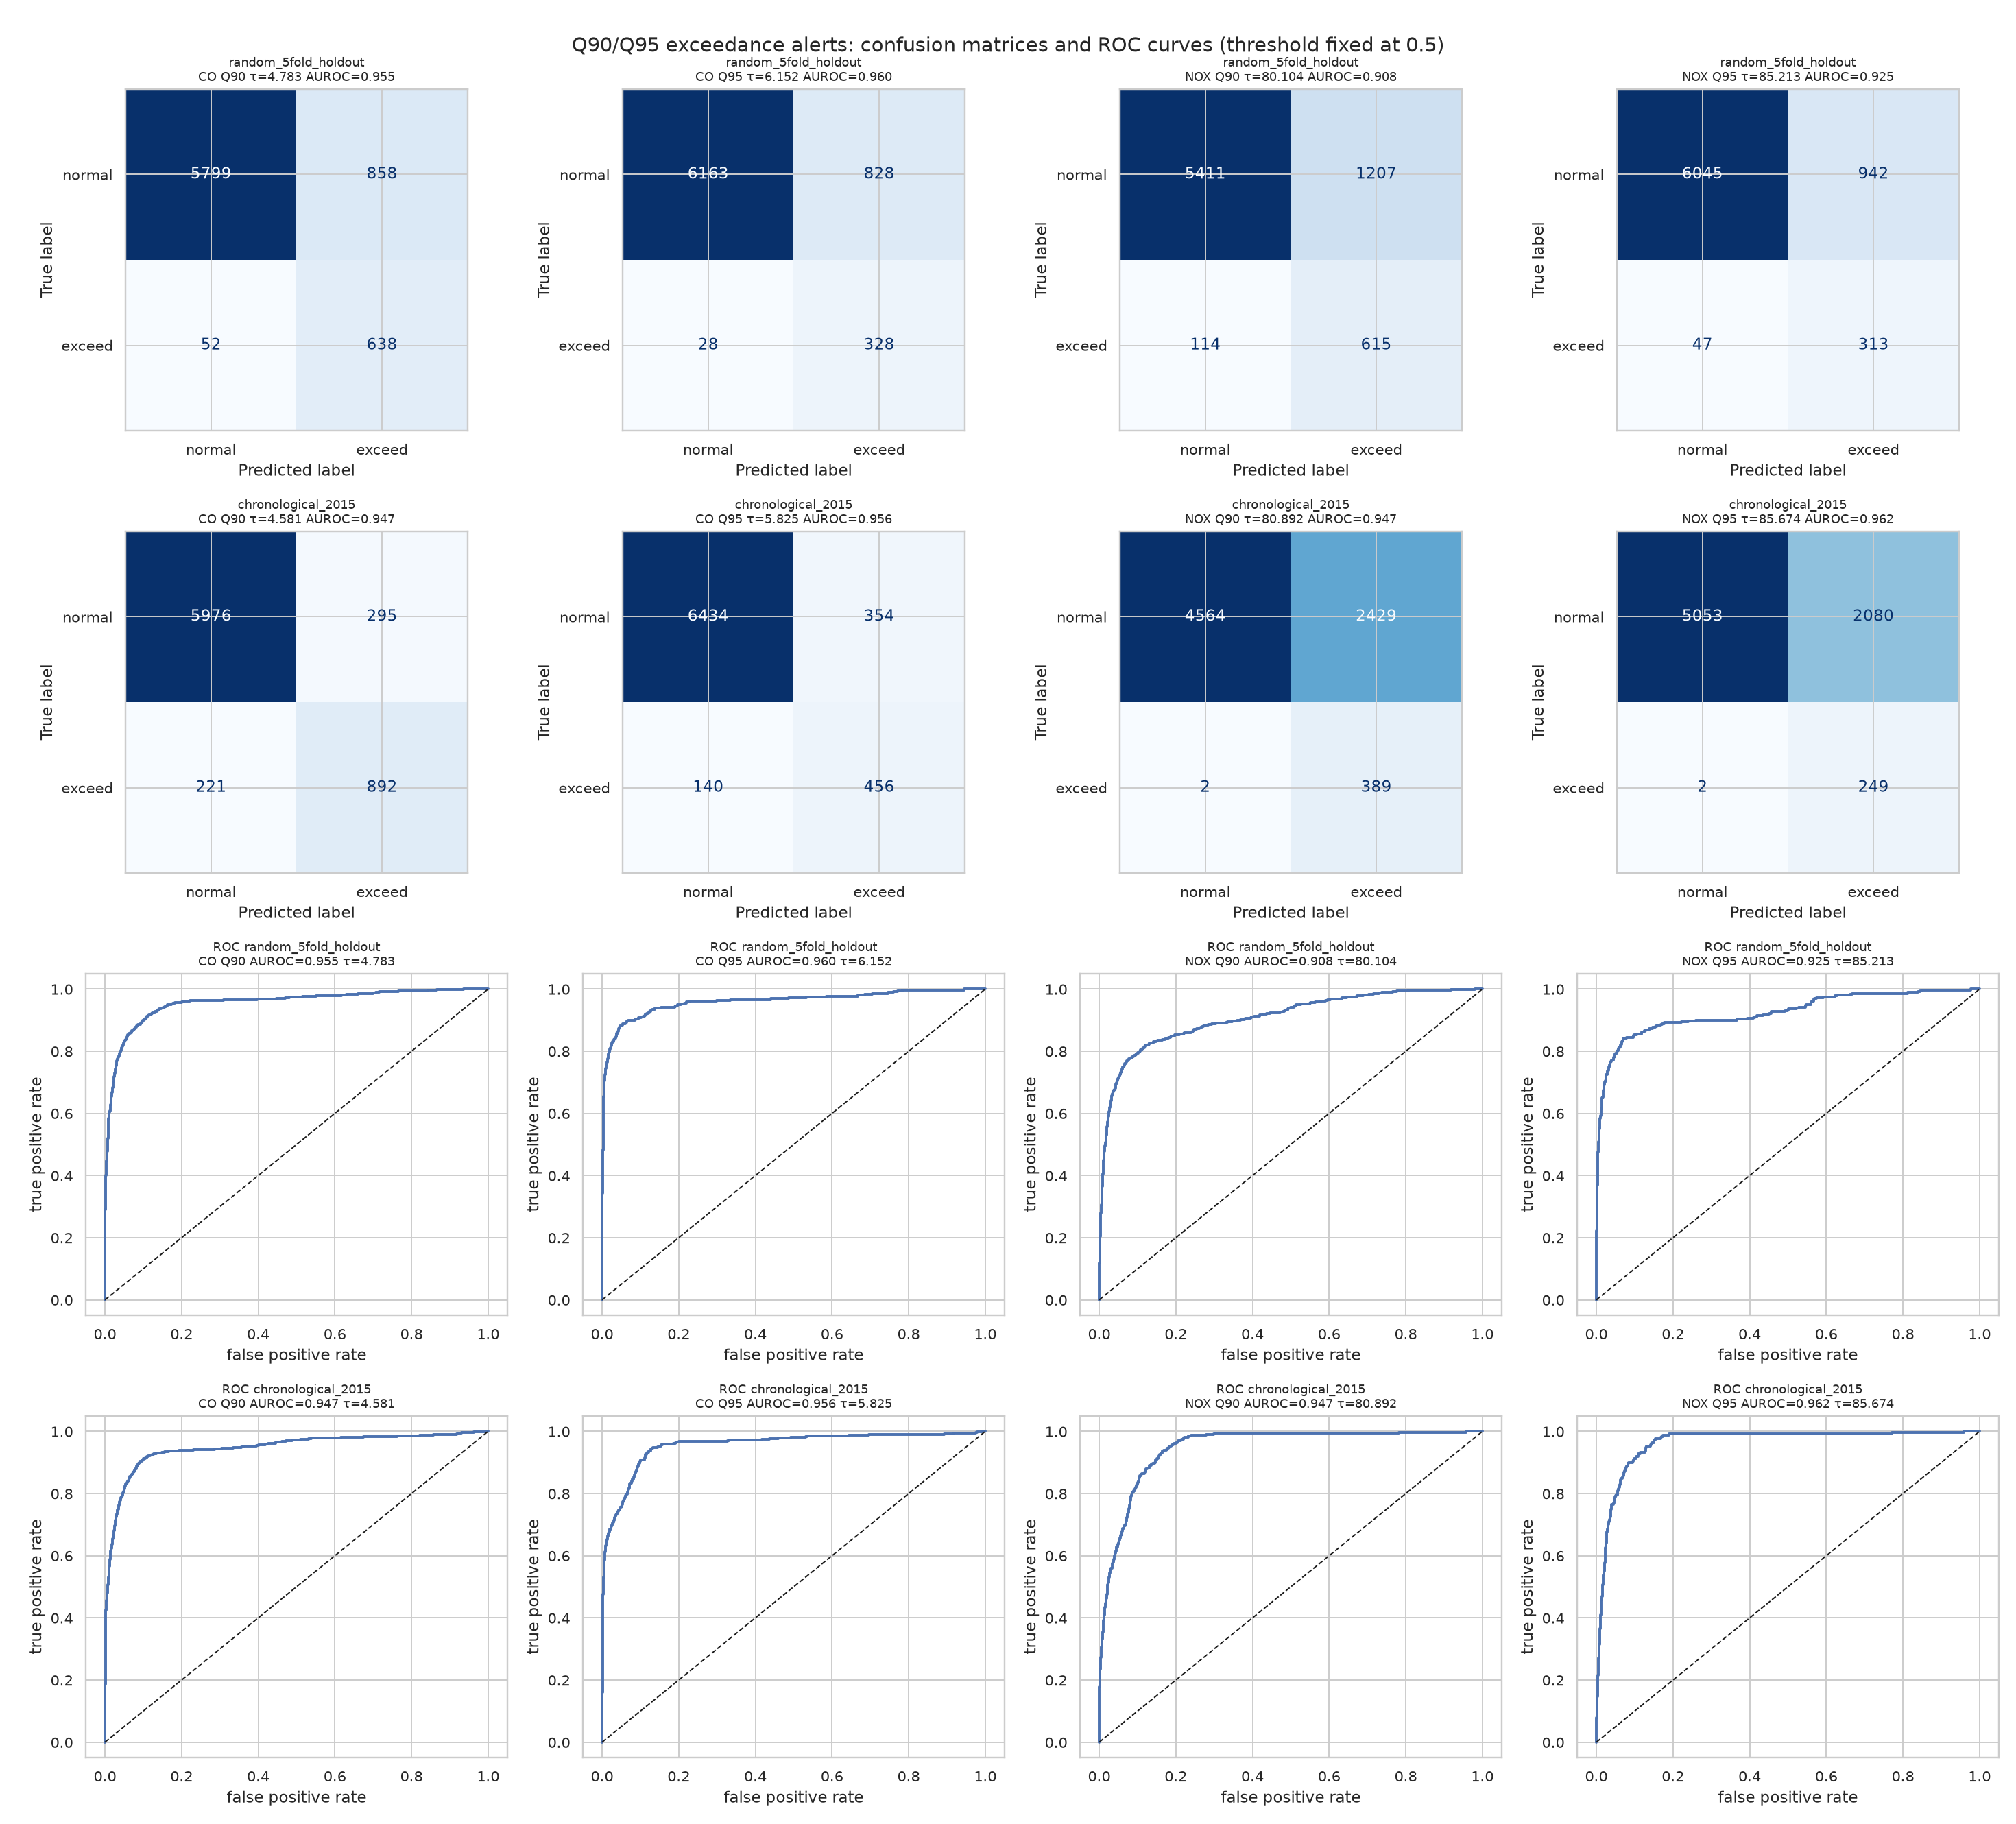

Alert quality summary (recall / precision / AUROC):
            protocol target quantile  train_prevalence  test_recall  test_precision  test_roc_auc
random_5fold_holdout     CO      Q90          0.100014     0.924638        0.426471      0.955433
random_5fold_holdout     CO      Q95          0.050024     0.921348        0.283737      0.960386
random_5fold_holdout    NOX      Q90          0.099980     0.843621        0.337541      0.908375
random_5fold_holdout    NOX      Q95          0.050024     0.869444        0.249402      0.925169
  chronological_2015     CO      Q90          0.100003     0.801438        0.751474      0.947266
  chronological_2015     CO      Q95          0.050019     0.765101        0.562963      0.955715
  chronological_2015    NOX      Q90          0.100003     0.994885        0.138041      0.947481
  chronological_2015    NOX      Q95          0.050019     0.992032        0.106913      0.962248


In [7]:
run_stage("04_logistic_and_parity.py")
table07 = pd.read_csv(ROOT / "results" / "table07_logistic_exceedance_metrics.csv")
display(table07)
display(Image(filename=str(ROOT / "figures" / "fig08_logistic_confusion_roc.png"), width=1100))
print("Alert quality summary (recall / precision / AUROC):")
print(
    table07[
        ["protocol", "target", "quantile", "train_prevalence", "test_recall", "test_precision", "test_roc_auc"]
    ].to_string(index=False)
)

## Overall conclusions

- The pipeline honors the verified 36,733-row data contract with zero
  imputation and zero row deletion.
- PCA/K-Means describe three load regimes; they are explanatory only.
- Regularized nonlinear models improve interpolation accuracy, but the locked
  2015 evaluation is the credible generalization estimate.
- Training-only IQR/3-sigma trimming is reported transparently against
  identical untrimmed test rows; emissions spikes remain in every test set.
- Logistic Q90/Q95 alerts provide high-recall screening. Deployment requires
  drift monitoring, scheduled refits and human review of alerts.
